# Movie Recommender — Content-Based Filtering with Cosine Similarity

Recommends movies similar to a given title, using the **MovieLens 32M** dataset.
Each movie is described by its genres plus the tags real users applied to it;
those descriptions are vectorised with TF-IDF and compared with cosine
similarity. An interactive widget lets you type a title and get recommendations.

**Dataset:** [MovieLens 32M](https://files.grouplens.org/datasets/movielens/ml-32m.zip)
— 87,585 movies · 32,000,204 ratings · 2,000,072 tags.

## 1. Setup

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

DATA_DIR = "ml-32m"

### Get the data

Downloads only if `ml-32m/` isn't already present, so re-running is cheap.

In [2]:
if not os.path.isdir(DATA_DIR):
    !wget -q https://files.grouplens.org/datasets/movielens/ml-32m.zip
    !unzip -q ml-32m.zip
    !rm ml-32m.zip
    print("downloaded and extracted")
else:
    print(f"{DATA_DIR} already present - skipping download")

print(*sorted(os.listdir(DATA_DIR)), sep="\n")

ml-32m already present - skipping download
README.txt
checksums.txt
links.csv
movies.csv
ratings.csv
tags.csv


## 2. Load the data

In [3]:
df_movies = pd.read_csv(
    f"{DATA_DIR}/movies.csv",
    dtype={"movieId": "int32", "title": "str", "genres": "str"},
)
df_ratings = pd.read_csv(
    f"{DATA_DIR}/ratings.csv",
    dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"},
)
df_tags = pd.read_csv(
    f"{DATA_DIR}/tags.csv",
    dtype={"userId": "int32", "movieId": "int32", "tag": "str", "timestamp": "int64"},
)

print(f"movies  {df_movies.shape}")
print(f"ratings {df_ratings.shape}")
print(f"tags    {df_tags.shape}")

movies  (87585, 3)
ratings (32000204, 4)
tags    (2000072, 4)


In [4]:
display(df_movies.head())
display(df_ratings.head())
display(df_tags.head())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


## 3. Data preparation

Add each movie's average user rating, and fold the user tags in as descriptive
text — tags are the strongest signal for "what is this film actually like".

In [5]:
movie_mean_rating = df_ratings.groupby("movieId")["rating"].mean().rename("rating")
rating_counts = df_ratings.groupby("movieId")["rating"].size().rename("num_ratings")

df_movies = df_movies.merge(movie_mean_rating, on="movieId", how="left")
df_movies = df_movies.merge(rating_counts, on="movieId", how="left")
df_movies[["rating", "num_ratings"]] = df_movies[["rating", "num_ratings"]].fillna(0)
df_movies["rating"] = df_movies["rating"].round(3)

# Normalised title key for lookups.
# MovieLens stores the article at the end ("Matrix, The (1999)"), so fold it
# back to the front and strip punctuation, or users can never find those films
# by the name everyone actually uses.
def normalise_title(t):
    t = re.sub(r"\s*\(\d{4}\)\s*$", "", str(t)).strip().lower()
    t = t.replace("&", " and ")
    m = re.match(r"^(.*),\s*(the|a|an)$", t)
    if m:
        t = f"{m.group(2)} {m.group(1)}"
    t = re.sub(r"[^a-z0-9 ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


df_movies["title_lower"] = df_movies["title"].map(normalise_title)
print("sample keys:", df_movies["title_lower"].iloc[[0, 2]].tolist())
print("'The Matrix' key:", df_movies.loc[df_movies['title'].str.contains('Matrix, The', na=False), 'title_lower'].tolist())

print(f"movies with at least one rating: {(df_movies['num_ratings'] > 0).sum()}")
df_movies.head()

sample keys: ['toy story', 'grumpier old men']
'The Matrix' key: ['the matrix']
movies with at least one rating: 84432


,movieId,title,genres,rating,num_ratings,title_lower
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.897,68997.0,toy story
1,2,Jumanji (1995),Adventure|Children|Fantasy,3.276,28904.0,jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,3.139,13134.0,grumpier old men
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,2.845,2806.0,waiting to exhale
4,5,Father of the Bride Part II (1995),Comedy,3.060,13154.0,father of the bride part ii


In [6]:
# Collapse each movie's tags into one space-separated string
movie_tags = (
    df_tags.assign(tag=df_tags["tag"].fillna("").str.replace("|", " ", regex=False))
    .groupby("movieId")["tag"]
    .apply(lambda s: " ".join(s))
    .rename("tags")
    .reset_index()
)

df_movies = df_movies.merge(movie_tags, on="movieId", how="left")
df_movies["tags"] = df_movies["tags"].fillna("")

print(f"movies with tags: {(df_movies['tags'] != '').sum()}")
df_movies[["title", "genres", "tags"]].head()

movies with tags: 51323


,title,genres,tags
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,children Disney animation children Disney Disney pixar animation funny Pixar...
1,Jumanji (1995),Adventure|Children|Fantasy,Robin Williams fantasy Robin Williams time travel animals childhood recaptur...
2,Grumpier Old Men (1995),Comedy|Romance,comedinha de velhinhos engraÃƒÂ§ada comedinha de velhinhos engraÃ§ada grun r...
3,Waiting to Exhale (1995),Comedy|Drama|Romance,characters slurs based on novel or book chick flick divorce interracial rela...
4,Father of the Bride Part II (1995),Comedy,Fantasy pregnancy remake family Steve Martin steve martin Steve Martin aging...


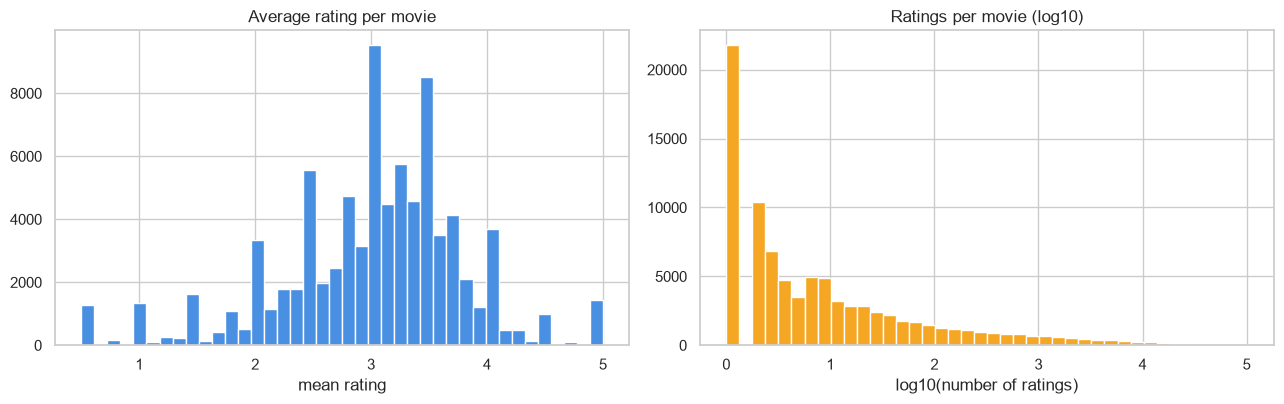

median ratings per movie: 5


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].hist(df_movies.loc[df_movies.num_ratings > 0, "rating"], bins=40, color="#4A90E2")
axes[0].set_title("Average rating per movie")
axes[0].set_xlabel("mean rating")

rated = df_movies["num_ratings"].clip(lower=1)
axes[1].hist(np.log10(rated), bins=40, color="#F5A623")
axes[1].set_title("Ratings per movie (log10)")
axes[1].set_xlabel("log10(number of ratings)")

plt.tight_layout()
plt.show()

print(f"median ratings per movie: {df_movies['num_ratings'].median():.0f}")

## 4. Feature engineering

Combine genres and tags into a single text field per movie. Genres are short and
consistent; tags are free text. TF-IDF weights a tag that appears for only a
handful of films far more heavily than `Drama`, which appears for thousands.

In [8]:
df_movies["combined_features"] = (
    df_movies["genres"].str.replace("|", " ", regex=False) + " " + df_movies["tags"]
)
df_movies[["title", "combined_features"]].head(3)

,title,combined_features
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy children Disney animation childr...
1,Jumanji (1995),Adventure Children Fantasy Robin Williams fantasy Robin Williams time travel...
2,Grumpier Old Men (1995),Comedy Romance comedinha de velhinhos engraÃƒÂ§ada comedinha de velhinhos en...


In [9]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=20_000,   # caps memory; the tail of the vocabulary is noise
    ngram_range=(1, 2),    # bigrams keep "based on novel" style tags meaningful
    min_df=2,
)
tfidf_matrix = tfidf.fit_transform(df_movies["combined_features"])

print("TF-IDF matrix:", tfidf_matrix.shape)
print("non-zero entries:", tfidf_matrix.nnz)

TF-IDF matrix: (87585, 20000)
non-zero entries: 2002265


## 5. Similarity — computed on demand

A full pairwise matrix would be:

```python
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
```

With 87,585 movies that is an 87,585 × 87,585 matrix — **7.7 billion** entries,
or ~61 GB as `float64`, which does not fit in memory on an ordinary machine. So
it is not built.

A query only ever needs the *one* row for the movie asked about. Comparing that single vector against the matrix is a
1 × 87,585 result — a few hundred kilobytes, computed in milliseconds.

In [10]:
def find_movie_index(title, threshold=0.6):
    '''Find the row index of a movie by title. Year and word order are ignored.'''
    query = normalise_title(title)
    if not query:
        return None

    # title_lower is already normalised the same way
    titles = df_movies["title_lower"]

    exact = df_movies.index[titles == query]
    if len(exact):
        return int(exact[0])

    # fall back to substring match, preferring the most-rated candidate
    hits = df_movies[titles.str.contains(re.escape(query), na=False)]
    if hits.empty:
        return None

    # only accept if the query covers a large share of the candidate title
    hits = hits[hits["title_lower"].map(lambda t: len(query) / max(len(t), 1)) >= threshold]
    if hits.empty:
        return None
    return int(hits["num_ratings"].idxmax())


def get_recommendations(title, num_recommendations=5):
    """Return the N movies most similar to `title` as a DataFrame."""
    idx = find_movie_index(title)
    if idx is None:
        return f"Movie '{title}' not found in the dataset."

    # One row of similarity scores, computed on demand - no full matrix
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).ravel()

    # Exclude the movie itself and other entries sharing its exact title
    scores[idx] = -1.0

    top = np.argpartition(scores, -num_recommendations)[-num_recommendations:]
    top = top[np.argsort(scores[top])[::-1]]

    out = df_movies.loc[top, ["title", "genres", "rating", "num_ratings"]].copy()
    out["similarity"] = scores[top].round(3)
    return out.reset_index(drop=True)

### Try it

In [11]:
get_recommendations("Toy Story")

,title,genres,rating,num_ratings,similarity
0,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.812,32683.0,0.859
1,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,3.558,26736.0,0.744
2,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,3.828,20327.0,0.636
3,Finding Dory (2016),Adventure|Animation|Comedy,3.538,5624.0,0.621
4,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.837,46036.0,0.606


In [12]:
get_recommendations("The Matrix")

,title,genres,rating,num_ratings,similarity
0,"Matrix Reloaded, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,3.373,29835.0,0.852
1,"Matrix Revolutions, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,3.236,23699.0,0.784
2,Tron (1982),Action|Adventure|Sci-Fi,3.335,11973.0,0.494
3,Dark City (1998),Adventure|Film-Noir|Sci-Fi|Thriller,3.804,14404.0,0.482
4,Avalon (2001),Drama|Fantasy|Sci-Fi,3.417,744.0,0.481


In [13]:
get_recommendations("Remember the Titans")

,title,genres,rating,num_ratings,similarity
0,Rudy (1993),Drama,3.536,8155.0,0.535
1,Friday Night Lights (2004),Action|Drama,3.542,1905.0,0.522
2,Gridiron Gang (2006),Drama,3.305,464.0,0.521
3,"Express, The (2008)",Drama,3.488,256.0,0.505
4,Invincible (2006),Drama,3.563,1313.0,0.503


### Sanity check: the best-rated films of a year

A quick way to confirm the data merged correctly.

In [14]:
df_movies["year"] = pd.to_numeric(
    df_movies["title"].str.extract(r"\((\d{4})\)$")[0], errors="coerce"
)

top_2023 = (
    df_movies[(df_movies["year"] == 2023) & (df_movies["num_ratings"] >= 500)]
    .sort_values("rating", ascending=False)
    .head(10)[["title", "genres", "rating", "num_ratings"]]
)
top_2023

,title,genres,rating,num_ratings
85883,Spider-Man: Across the Spider-Verse (2023),Action|Adventure|Animation|Sci-Fi,4.207,1133.0
86162,Oppenheimer (2023),Drama,4.083,1152.0
85474,Guardians of the Galaxy Volume 3 (2023),Action|Adventure|Sci-Fi,3.729,980.0
85125,John Wick: Chapter 4 (2023),Action|Crime|Thriller,3.717,861.0
85445,Dungeons & Dragons: Honor Among Thieves (2023),Action|Adventure|Fantasy,3.691,740.0
86382,Barbie (2023),Comedy,3.668,939.0
85629,The Super Mario Bros. Movie (2023),Adventure|Animation|Children|Comedy|Fantasy,3.288,538.0
84429,Ant-Man and the Wasp: Quantumania (2023),Adventure|Comedy|Sci-Fi,2.797,501.0


## 6. Interactive widget

Type a title and get recommendations without re-running cells.

In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output

title_box = widgets.Text(
    placeholder="e.g. Toy Story",
    description="Movie:",
    layout=widgets.Layout(width="380px"),
)
n_box = widgets.IntSlider(value=5, min=1, max=15, description="How many:")
button = widgets.Button(description="Recommend", button_style="primary")
out = widgets.Output()


def run(_=None):
    with out:
        clear_output(wait=True)
        result = get_recommendations(title_box.value.strip(), n_box.value)
        if isinstance(result, str):
            print(result)
        else:
            display(result)


button.on_click(run)
display(widgets.VBox([widgets.HBox([title_box, n_box, button]), out]))

## 7. Summary

- 87,585 movies described by genres + 2M user tags.
- TF-IDF over that text, capped at 20,000 features with bigrams.
- Cosine similarity computed **on demand** (1 × N), not as a full N × N matrix —
  this is what makes the notebook run in a normal amount of memory.
- `get_recommendations("Toy Story")` returns the closest matches with their
  genres, average rating and similarity score.

**Limitations.** This is content-based only: it uses no collaborative signal
(what *users* who liked a film went on to like), and it treats every tag as
equally trustworthy, with no weighting by who applied it. A rating-prediction
model (matrix factorisation, or an ALS-based recommender) would answer a
different and harder question — predicting a rating rather than finding
similar items.